# The **SampleModel** class
<h3> The class representing the model of the physical sample </h3>

The [**SampleModel**](https://easyscience.github.io/imaging-lib/latest/api-reference/sample_model/sample_model/) consists of two objects:
1. A full **atomistic model** of the crystallographic `Lattice` of the sample, i.e. the crystallographic _unit cell_ and the atoms within it.
2. A small class representing the `SampleProperties` which does **not** belong in a crystallographic model: Currently just the sample **temperature** and the **sample thickness**.

## The `SampleProperties` class
The **SampleProperties** object is neccesary to construct a `SampleModel`. It provides the `SampleModel` with the remaining parameters needed to fully describe the physical sample, those that don't fit in the atomic crystallographic model.<br>
Currently this only includes the ambient **temperature** and **sample_thickness**, but this will likely change in the future.

In [1]:
from easyimaging.sample_model import SampleProperties

sample_properties = SampleProperties(temperature=300, sample_thickness=1)

The **temperature** is initially in _Kelvin_ and the **sample_thickness** is in _centimeters_.

Both of these parameters are **EasyScience** [`Parameters`](https://easyscience.github.io/core/latest/api-reference/variable/#easyscience.variable.parameter), meaning that you can set their **min**/**max** bounds, i.e. the lowest and highest values they can assume, convert their unit to a **compatible** unit of your choice and make them **dependent** on each other or other parameters.

In [2]:
sample_properties.temperature.min = 100
sample_properties.temperature.max = 500
sample_properties.sample_thickness.convert_unit('mm')
sample_properties.sample_thickness = 40

---
⚠️ **Warning**

Take care when both converting the units and setting values of parameters, that setting their values respects the parameters **current** unit.<br>
So that you don't accidentally set a parameter to $15$ cm, when you wanted $15$ mm.

---
The **SampleProperties** class (and all other model-related classes), implements the method `get_all_parameters`, which returns a list of all [`Parameters`](https://easyscience.github.io/core/latest/api-reference/variable/#easyscience.variable.parameter) contained in the object.

In [3]:
sample_properties.get_all_parameters()

[<Parameter 'SampleProperties_0_sample_thickness_0': 40.0000 mm (fixed), bounds=[0.0001:inf]>,
 <Parameter 'SampleProperties_0_temperature_0': 300.0000 K (fixed), bounds=[100.0:500.0]>]

---
ℹ️ **Note**

Notice that both parameter are **(fixed)**. All parameters are **fixed** by default, to allow them to vary during a fit, set their `fixed` property to false.

Notice also that many parameters come with pre-defined **min**/**max** bounds, such as the `sample_thickness` here being bound to the interval $]0:\infty]$, these usually represent the physical limits of the parameters and any changes to the bounds shouldn't exceed these.<br>
For example, one shouldn't set the **min** of the `sample_thickness` to a negative value, as a negative `sample_thickness` is unphysical and will have unintended consequences on calculations done with the model.

---

In [4]:
sample_properties.sample_thickness.fixed = False

## The `Lattice` class
The **Lattice** object is a full atomistic model describing the crystallography and atomic composition of the sample to be modelled.

The `Lattice` object can currently be created in 3 ways, in descending order of simplicity:
1. From scratch, with **all** the neccesary parameters of the `Lattice` defined by the user.
2. Using the `Lattice` class' convenience constructor methods: `cubic` or `hexagonal`.
3. Using the constructor functions in the [`easyimaging.sample_model.crystal`](https://easyscience.github.io/imaging-lib/dev/api-reference/sample_model/crystals/) module.

### Creating a `Lattice` from scratch
The unit cell of the crystallographic lattice is _univocally_ defined by its 6 parameters: <br>
The 3 lattice parameters / constants, $a$, $b$ and $c$, representing the lengts of the lattice vectors $\vec{a}$, $\vec{b}$ and $\vec{c}$, respectively / the sidelengths of the unit cell.<br>
And the 3 lattice angles $\alpha$, $\beta$ and $\gamma$, representing the angle between the lattice vectors ($\vec{b}$ and $\vec{c}$), ($\vec{a}$ and $\vec{c}$) and ($\vec{a}$ and $\vec{b}$), respectively.

In [5]:
from easyimaging.sample_model import Lattice

lattice = Lattice(length_a=3.21, length_b=3.21, length_c=5.21, alpha=90.0, beta=90.0, gamma=120.0)

Here, $\alpha$, $\beta$ and $\gamma$ is initially given in degrees, but can be converted to radians, and the lattice constants are initially in angstrom (Å).

---
⚠️ **Warning**

It is possible to set the values of the lattice angles $\alpha$, $\beta$ and $\gamma$, to values which does not make physical sense, like: $\alpha = \beta = \gamma = 170^\circ$.<br>
In such a case, the `Lattice` does not constitute a **physically valid** crystallographic lattice and attempting to do calculations with the model will raise an error.

---

Just like with the `SampleProperties` class, these parameters are **EasyScience** [`Parameters`](https://easyscience.github.io/core/latest/api-reference/variable/#easyscience.variable.parameter) and the `Lattice` class is a model class.

In [6]:
lattice.alpha.convert_unit('rad')
lattice.beta.convert_unit('rad')
lattice.length_a.convert_unit('nm')
lattice.length_c.min = 3.5
lattice.length_b.make_dependent_on(
    dependency_expression='a',
    dependency_map={'a': lattice.length_a},
)
lattice.length_a.fixed = False
lattice.get_all_parameters()

[<Parameter 'Lattice_0_angle_alpha_0': 1.5708 rad (fixed), bounds=[1.7453292519943296e-05:3.141575200297273]>,
 <Parameter 'Lattice_0_angle_beta_0': 1.5708 rad (fixed), bounds=[1.7453292519943296e-05:3.141575200297273]>,
 <Parameter 'Lattice_0_angle_gamma_0': 120.0000 deg (fixed), bounds=[0.001:179.999]>,
 <Parameter 'Lattice_0_length_a_0': 0.3210 nm, bounds=[9.999999999999999e-05:inf]>,
 <Parameter 'Lattice_0_length_b_0': 0.3210 nm (dependent), bounds=[9.999999999999999e-05:inf]>,
 <Parameter 'Lattice_0_length_c_0': 5.2100 Å (fixed), bounds=[3.5:inf]>]

---
ℹ️ **Note**

Notice that the parameters **min**/**max** also gets converted, when you convert the unit, as evidenced by the default min/max of the angle parameters at $]0:180[$, which here was converted to $]0:\pi[$ for the $\alpha$ and $\beta$ parameters, when these were converted to radians.

---

---
⚠️ **Warning**

Be careful if freeing the `Lattice` angles to vary during a fit, as the minimizer might change them into a **physically invalid** set (see the warning above) during fitting, thereby crashing the fit.<br>
Always ensure that freed `Lattice` angles fulfil the sum requirement $\alpha + \beta + \gamma < 360^\circ$ and the triangle inequalities ($\alpha + \beta > \gamma$, $\alpha + \gamma > \beta$ and $\beta + \gamma > \alpha$). This can be done with **dependent** parameters, see below.

---

Here we also made our first **dependent** parameter. A dependent parameter is a parameter whose value is fixed to some combination of other parameters, here we just set `length_b` to be equal to `length_a`.<br>
Values of **dependent** parameters cannot be changed, neither manually or by the fitting engine. Their value only gets updated, when the parameters that they depend on gets updated, in this case when `length_a` gets updated.<br>

In [7]:
lattice.length_b.value = 2

AttributeError: This is a dependent parameter, its value cannot be set directly.

In [8]:
lattice.length_a.value = 0.21
lattice.length_a.min = 0.1
print(lattice.length_a)
print(lattice.length_b)

<Parameter 'Lattice_0_length_a_0': 0.2100 nm, bounds=[0.1:inf]>
<Parameter 'Lattice_0_length_b_0': 0.2100 nm (dependent), bounds=[0.1:inf]>


To make a parameter **dependent**, use the `make_dependent_on` method, as shown above. To make it **independent** again, so that it is free to be fitted or changed manually, use the `make_independent` method.<br>
For more details, see the `Parameter` API documentation [here](https://easyscience.github.io/core/latest/api-reference/variable/#easyscience.variable.parameter.Parameter.make_dependent_on).

---
💡 **Hint**

All model classes implements functions other than `get_all_parameters`, which returns an **expanded** _or_ **reduced** list of parameters in the object.

1. `get_all_variables` will return all **EasyScience** [`Parameters`](https://easyscience.github.io/core/latest/api-reference/variable/#easyscience.variable.parameter) **AND** [`Descriptors`](https://easyscience.github.io/core/latest/api-reference/variable/#easyscience.variable.descriptor_number), if any _exists_ in the object.
2. `get_all_parameters` will return **ONLY** the `Parameters` in the object.
3. `get_fittable_parameters` will filter out all **dependent** `Parameters`.
4. `get_free_parameters` will also filter out all **fixed** `Parameters`, returning only those currently free to be fitted.

---

In [9]:
lattice.get_fittable_parameters()

[<Parameter 'Lattice_0_angle_alpha_0': 1.5708 rad (fixed), bounds=[1.7453292519943296e-05:3.141575200297273]>,
 <Parameter 'Lattice_0_angle_beta_0': 1.5708 rad (fixed), bounds=[1.7453292519943296e-05:3.141575200297273]>,
 <Parameter 'Lattice_0_angle_gamma_0': 120.0000 deg (fixed), bounds=[0.001:179.999]>,
 <Parameter 'Lattice_0_length_a_0': 0.2100 nm, bounds=[0.1:inf]>,
 <Parameter 'Lattice_0_length_c_0': 5.2100 Å (fixed), bounds=[3.5:inf]>]

In [10]:
lattice.get_free_parameters()

[<Parameter 'Lattice_0_length_a_0': 0.2100 nm, bounds=[0.1:inf]>]

### Creating a `Lattice` from convenience constructor methods
The `Lattice` class currently has support for 2 constructor methods, `cubic` and `hexagonal`, to easily create a **cubic** or a **hexagonal** unit cell.<br>
Above, we created a hexagonal unit cell from scratch. Constructing the same `Lattice` is much easier with the `hexagonal` method:

In [11]:
hexagonal_lattice = Lattice.hexagonal(length_a=2.79, length_c=5.21)
hexagonal_lattice.get_all_parameters()

[<Parameter 'HexagonalLattice_0_angle_alpha_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'HexagonalLattice_0_angle_beta_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'HexagonalLattice_0_angle_gamma_0': 120.0000 deg (dependent), bounds=[0.0013333333333333333:239.99866666666665]>,
 <Parameter 'HexagonalLattice_0_length_a_0': 2.7900 Å (fixed), bounds=[0.001:inf]>,
 <Parameter 'HexagonalLattice_0_length_b_0': 2.7900 Å (dependent), bounds=[0.001:inf]>,
 <Parameter 'HexagonalLattice_0_length_c_0': 5.2100 Å (fixed), bounds=[0.001:inf]>]

---
ℹ️ **Note**

Notice that the name of the parameters all begin with `HexagonalLattice`, rather than just `Lattice` as above, because the object was created with the `hexagonal` method.

---

Using the `hexagonal` constructor method, the angles $\alpha$, $\beta$ and $\gamma$ in the `Lattice`, are set to $90^\circ$, $90^\circ$ and $120^\circ$, respectively, and is **"locked in"** as dependent parameters.<br>
Additionally, the `length_b` parameter automatically gets set to be a dependent parameter equal to `length_a`, just like we did in the above "from scratch" example:

In [12]:
hexagonal_lattice.length_a = 3.21
print(hexagonal_lattice.length_a)
print(hexagonal_lattice.length_b)

<Parameter 'HexagonalLattice_0_length_a_0': 3.2100 Å (fixed), bounds=[0.001:inf]>
<Parameter 'HexagonalLattice_0_length_b_0': 3.2100 Å (dependent), bounds=[0.001:inf]>


The `cubic` method is similar to the `hexagonal` method, except that $\gamma$ is also set to $90^\circ$, instead of $120^\circ$, and the `length_c` parameter is also set to be a dependent parameter equal to `length_a`.

In [13]:
cubic_lattice = Lattice.cubic(length_a=2.1)
cubic_lattice.get_all_parameters()

[<Parameter 'CubicLattice_0_angle_alpha_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'CubicLattice_0_angle_beta_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'CubicLattice_0_angle_gamma_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'CubicLattice_0_length_a_0': 2.1000 Å (fixed), bounds=[0.001:inf]>,
 <Parameter 'CubicLattice_0_length_b_0': 2.1000 Å (dependent), bounds=[0.001:inf]>,
 <Parameter 'CubicLattice_0_length_c_0': 2.1000 Å (dependent), bounds=[0.001:inf]>]

### The `AtomSite` class
A unit cell by itself does not constitute a complete crystallographic `Lattice`, and as such our `Lattice` objects will currently not work, as exemplified when trying to get their crystallographic spacegroups:

In [14]:
cubic_lattice.spacegroup

LatticeError: Lattice must have at least one atom site to be a valid crystal structure.

As the error informs us, we **need** to insert _at least_ 1 atom into our unit cell to make it a valid crystallographic lattice.

We do this with the `AtomSite` class. The `AtomSite` object represents a "site", i.e. a specific **position** in the unit cell, its occupying **atomic species** and its vibrational **dynamics**.<br>

The **position** is given in fractional coordinates `fract_a`, `fract_b` and `fract_c`, corresponding to fractions of the lattice vectors $\vec{a}$, $\vec{b}$ and $\vec{c}$, respectively.

---
💡 **Hint**

The lattice vectors of a `Lattice`'s unit cell can be viewed in cartesian coordinates by using the `lattice_vectors` property.

---

In [15]:
hexagonal_lattice.lattice_vectors

[[3.21, 0.0, 0.0],
 [-1.6049999999999993, 2.779941546148048, 0.0],
 [3.190204911778855e-16, 5.525596993756764e-16, 5.21]]

The **atomic species** of an `AtomSite` object refers to the kind of `Atom` occupying it, given by the `atom` argument.<br>
All elements and _most_ common **isotopes** of each element are supported, see the full list of recognized `Atoms` in the [documentation](https://easyscience.github.io/imaging-lib/dev/api-reference/sample_model/atoms/).

When constructing the `AtomSite` object, supplying the **vibrational dynamics** argument, the `debye_temperature`, is technically optional. <br>

---
⚠️ **Warning**

When the `debye_temperature` is **not** provided by the user, a default Debye temperature of 300 K is used, which can potentially lead to completely wrong model calculations.

---

In [16]:
from easyimaging.sample_model import Atoms
from easyimaging.sample_model import AtomSite

first_site = AtomSite(atom=Atoms.Mg, fract_a=0, fract_b=0, fract_c=0)

The **vibrational dynamics** of the `AtomSite` is modeled by an _idealised_ phonon dispersion for a given `debye_temperature`.<br>
There are plans in the future, to also allow using an **isotropic displacement parameter** $U_\text{iso}$, at a given temperature, to determine the _idealised_ phonon dispersion curve.<br>
If you only have an $U_\text{iso}$ for the material you wish to model, you can use the high-temperature ($T\gg T_D$) Debye approximation:
```math
T_D \approx \sqrt{\frac{3\hbar^2 T}{m k_B U_\text{iso}}}
```
Where $T_D$ is the `debye_temperature`, $T$ is the temperature that $U_\text{iso}$ was measured at, $\hbar$ is the reduced Planck constant, $k_B$ is the Boltzmann constant and $m$ is the mass of the atom.

The `AtomSite` object can be inserted into the `Lattice` through the `atom_sites` argument, either when constructing the `Lattice` from scratch, or when using the `cubic`/`hexagonal` constructor methods. <br> 
It is also possible to append to/extend an existing `Lattice`'s `atom_sites` [EasyList](https://easyscience.github.io/core/latest/api-reference/base_classes/#easyscience.base_classes.easy_list) (empty `Lattice`'s are created with a length 0 `atom_sites` list).

In [17]:
second_site = AtomSite(atom=Atoms.Mg, fract_a=2 / 3, fract_b=1 / 3, fract_c=0.5, debye_temperature=400.0)
hexagonal_lattice.atom_sites.extend([first_site, second_site])

The `fract_a`, `fract_b`, `fract_c` and `debye_temperature` properties are all **EasyScience** [`Parameters`](https://easyscience.github.io/core/latest/api-reference/variable/#easyscience.variable.parameter) and the `AtomSite` is a model class, hence it supports the `get_all_parameters` method and its siblings.

In [18]:
first_site.get_all_parameters()

[<Parameter 'Mg AtomSite_0_debye_temperature_0': 300.0000 K (fixed), bounds=[1e-09:inf]>,
 <Parameter 'Mg AtomSite_0_fract_a_0': 0.0000 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_0_fract_b_0': 0.0000 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_0_fract_c_0': 0.0000 (fixed), bounds=[0.0:1.0]>]

---
ℹ️ **Note**

An `AtomSite` object gets named after the `Atom` which occupies it upon its **construction**, and **all** its parameters are then named after _it_, as seen above.

---

When `AtomSite`'s are inserted into a `Lattice`, their `Parameters` also show up when calling `get_all_parameters` on the `Lattice` object, since they are now also parameters of the full crystallographic `Lattice` model.

In [19]:
hexagonal_lattice.get_all_parameters()

[<Parameter 'HexagonalLattice_0_angle_alpha_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'Mg AtomSite_0_debye_temperature_0': 300.0000 K (fixed), bounds=[1e-09:inf]>,
 <Parameter 'Mg AtomSite_0_fract_a_0': 0.0000 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_0_fract_b_0': 0.0000 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_0_fract_c_0': 0.0000 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_1_debye_temperature_0': 400.0000 K (fixed), bounds=[1e-09:inf]>,
 <Parameter 'Mg AtomSite_1_fract_a_0': 0.6667 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_1_fract_b_0': 0.3333 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_1_fract_c_0': 0.5000 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'HexagonalLattice_0_angle_beta_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'HexagonalLattice_0_angle_gamma_0': 120.0000 deg (dependent), bounds=[0.0013333333333333333:239.99866666666665]>,
 <Parameter 'HexagonalLattice_0_length_a_0': 3.2100 Å (

As seen above, the list of `Parameters` quickly gets unmanageable when inserting `AtomSites` into a `Lattice`, hence filtering them by using the `get_free_parameters` and `get_fittable_parameters` can be quite useful, especially when calling them on sub-groups of the model, like specific `AtomSites`.

### Spacegroup and visualization of the `Lattice`
As mentioned earlier, a `Lattice` needs to contain **at minimum** 1 `AtomSite` to constitute a valid lattice, but most will contain many more. A _diamond lattice_, for example, contains 8 atoms in its minimal unit cell. 

Now that our `Lattice` is a **valid** `Lattice` object, it can be displayed in an interactive 3D display, using the `display` method.

In [20]:
hexagonal_lattice.display()

---
ℹ️ **Note**

An `AtomSite` on a unit cell boundary will be repeated on its mirror boundary/boundaries in the display of the `Lattice`.

---

When calculating the **symmetries** of a crystallographic lattice to determine its spacegroup, it is neccesary to distinguish between identical and unique atoms.<br>
Two `AtomSite`'s are considered identical only if they are occupied by the same `Atom` **and** have the same Debye temperature.

In [21]:
hexagonal_lattice.spacegroup

('P-6m2', 187)

Despite being an example of a **Hexagonal Close Packed** (HCP) lattice, which should have spacegroup "P6_3/mmc" in _Hermann-Mauguin_ notation, spacegroup number 194 in the International Union of Crystallography spacegroup table, our hexagonal lattice gets the **lower** symmetry spacegroup "P-6m2", 187.

This is due to our two `AtomSite`s having two different _debye_temperatures_, meaning that they get treated as two **unique** atoms, despite being occupied by the same `Atom` species. Setting their debye temperatures equal yields the correst spacegroup.

In [22]:
hexagonal_lattice.atom_sites[0].debye_temperature = 400.0
hexagonal_lattice.spacegroup

The atom site positions can be standardized with the `standardize_positions` method.


('P6_3/mmc', 194)

We now got the correct spacegroup, but we also got warning. While our `Lattice` is a perfectly valid HCP lattice, its origin is currently (0,0,0), which is **not** the standard origin for the HCP lattice.

Lattices with _non-standard_ origins **cannot** be used for calculations by `EasyImaging`s backend calculators. The origin of a `Lattice` object can be shifted to the standard origin by using the `standardize_positions` method.

In [23]:
hexagonal_lattice.standardize_positions()
print(hexagonal_lattice.spacegroup)
hexagonal_lattice.get_all_parameters()

('P6_3/mmc', 194)


[<Parameter 'HexagonalLattice_0_angle_alpha_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'Mg AtomSite_0_debye_temperature_0': 400.0000 K (fixed), bounds=[1e-09:inf]>,
 <Parameter 'Mg AtomSite_0_fract_a_0': 0.6667 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_0_fract_b_0': 0.3333 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_0_fract_c_0': 0.7500 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_1_debye_temperature_0': 400.0000 K (fixed), bounds=[1e-09:inf]>,
 <Parameter 'Mg AtomSite_1_fract_a_0': 0.3333 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_1_fract_b_0': 0.6667 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_1_fract_c_0': 0.2500 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'HexagonalLattice_0_angle_beta_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'HexagonalLattice_0_angle_gamma_0': 120.0000 deg (dependent), bounds=[0.0013333333333333333:239.99866666666665]>,
 <Parameter 'HexagonalLattice_0_length_a_0': 3.2100 Å (

We see that the spacegroup and lattice parameters are left unchanged, but the `AtomSite`s fractional coordinates were shifted to: $(\frac{1}{3}, \frac{2}{3}, \frac{1}{4})$ and $(\frac{2}{3}, \frac{1}{3}, \frac{3}{4})$, which are the standard positions for the HCP lattice.

In [24]:
hexagonal_lattice.display()

### Creating a `Lattice` with the `crystals` module
The `crystals` module contains a number of **convenience** functions to easily create **standard** crystal structures, like the HCP `Lattice` from above:

In [25]:
from easyimaging.sample_model.crystals import hexagonal_close_packed

new_hexagonal_lattice = hexagonal_close_packed(length_a=3.21, length_c=5.21, atom=Atoms.Mg, debye_temperature=400.0)
new_hexagonal_lattice.get_all_parameters()

[<Parameter 'Mg HCP Lattice_0_angle_alpha_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'Mg AtomSite_2_debye_temperature_0': 400.0000 K (fixed), bounds=[1e-09:inf]>,
 <Parameter 'Mg AtomSite_2_fract_a_0': 0.3333 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_2_fract_b_0': 0.6667 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_2_fract_c_0': 0.2500 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_3_debye_temperature_0': 400.0000 K (fixed), bounds=[1e-09:inf]>,
 <Parameter 'Mg AtomSite_3_fract_a_0': 0.6667 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_3_fract_b_0': 0.3333 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg AtomSite_3_fract_c_0': 0.7500 (fixed), bounds=[0.0:1.0]>,
 <Parameter 'Mg HCP Lattice_0_angle_beta_0': 90.0000 deg (dependent), bounds=[0.001:179.999]>,
 <Parameter 'Mg HCP Lattice_0_angle_gamma_0': 120.0000 deg (dependent), bounds=[0.0013333333333333333:239.99866666666665]>,
 <Parameter 'Mg HCP Lattice_0_length_a_0': 3.2100 Å (fixed), 

With these convenience functions, the `Lattice` automatically gets **populated** with `AtomSite`s in their standardized positions for the corresponding spacegroup.

---
ℹ️ **Note**

When a `Lattice` is created from the convencience functions in the `crystals` module, their initial name corresponds to the used function and provided `Atom`.<br>
For example, a hexagonal close packed (HCP) magnesium lattice gets named "Mg HCP Lattice".

---

In [26]:
new_hexagonal_lattice.display()

The `crystals` module contains a number of convenience constructor functions. See the full list [here](https://easyscience.github.io/imaging-lib/dev/api-reference/sample_model/crystals/#easyimaging.sample_model.crystals.hexagonal_close_packed).

In [27]:
from easyimaging.sample_model.crystals import zincblende

zincblende_lattice = zincblende(length_a=3.51, atom1=Atoms.Fe, atom2=Atoms.C)
zincblende_lattice.display()

Debye temperature not provided for 'FeC Zincblende Lattice_0' (atom1). Setting to default value of 300 K.
Debye temperature not provided for 'FeC Zincblende Lattice_0' (atom2). Setting to default value of 300 K.


## Constructing the `SampleModel`
With a **valid** `Lattice` and a `SampleProperties` object, a `SampleModel` can be created.

In [28]:
from easyimaging.sample_model import SampleModel

sample_model = SampleModel(
    lattice=new_hexagonal_lattice,
    sample_properties=sample_properties,
)

The `Lattice` of a `SampleModel` can be displayed by calling `display` directly on the `SampleModel`.

In [29]:
sample_model.display()

Assuming that the `Lattice` object of the `SampleModel` is **valid** and **standardized**, the `SampleModel` can be used to calculate the _model_ transmission spectrum for a given wavelength range, using the `spectrum` method.

---
ℹ️ **Note**

`EasyImaging` uses [`NCrystal`](https://github.com/mctools/ncrystal/wiki/) behind the scenes to calculate the _model_ transmission spectrum.
There are plans to also add support for the [`RITS`](https://mlfinfo.jp/bl22/en/GUI-RITS.html) library in the future, to perform these calculations.

---

In [30]:
import scipp as sc

wavelengths = sc.linspace(
    dim='t',
    start=1.5,
    stop=7.5,
    num=100,
    unit='angstrom',
)

spectrum = sample_model.spectrum(wavelengths)
spectrum

<scipp.DataArray>
Dimensions: Sizes[t:100, ]
Coordinates:
* wavelength                float64             [Å]  (t)  [1.5, 1.56061, ..., 7.43939, 7.5]
Data:
                            float64  [dimensionless]  (t)  [0.547402, 0.56368, ..., 0.855995, 0.855205]

The `spectrum` method accepts _wavelengths_ as either a python **list** or **tuple**, a [**numpy**](https://numpy.org/) array, or a [**scipp**](https://scipp.github.io/index.html) `Variable`.

It is recommended to use a [**scipp**](https://scipp.github.io/index.html) `Variable`, to ensure that the _unit_ is correct. If a `scipp` variable is given, as above, it is **required** to have dimension "_t_" for _time_ and be in a _unit_ of **length**, such as angstrom (Å).

If the _wavelengths_ is given as a python list or tuple, or as a numpy array, it will be **assumed** that the values are in units of angstrom (Å).

The output of the `spectrum` method is a Scipp [`DataArray`](https://scipp.github.io/generated/classes/scipp.DataArray.html). To get the spectrum values as a numpy array, call `.data.values` on it:

In [31]:
spectrum.data.values

array([0.54740242, 0.56367959, 0.5556129 , 0.55541706, 0.54387683,
       0.55793934, 0.55101492, 0.54085817, 0.54692301, 0.551741  ,
       0.57515107, 0.56232791, 0.56882672, 0.55618002, 0.54335403,
       0.53849537, 0.53485244, 0.52198698, 0.50902502, 0.5034437 ,
       0.52793182, 0.57288153, 0.56984864, 0.55896354, 0.60563317,
       0.59568976, 0.58591478, 0.57606919, 0.56616535, 0.60934775,
       0.60046157, 0.59151652, 0.58252166, 0.57348547, 0.56441546,
       0.55531919, 0.54620445, 0.53707833, 0.57051711, 0.56205032,
       0.55356835, 0.54507568, 0.53657622, 0.52807713, 0.51958354,
       0.5111006 , 0.50263239, 0.49418057, 0.48574064, 0.47727817,
       0.46886472, 0.4605383 , 0.45224849, 0.4440006 , 0.43579924,
       0.42764773, 0.41954395, 0.70353525, 0.69904424, 0.69452427,
       0.68997809, 0.68541183, 0.78611239, 0.78339292, 0.78065768,
       0.77789895, 0.77512022, 0.87939199, 0.87867986, 0.87796783,
       0.87725355, 0.8765292 , 0.87580874, 0.87507705, 0.87434

It is also possible to directly plot the `SampleModel`s transmission spectrum, using the `plot` method. Here the `wavelengths` are the same as in the `spectrum` method.

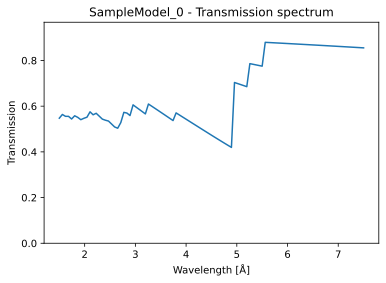

In [32]:
sample_model.plot(wavelengths)

This methods uses the [**plopp**](https://scipp.github.io/plopp/) library from scipp to splot the spectrum. It accepts customization options as optional keyword arguments, for the possible customization options, see: https://scipp.github.io/plopp/plotting/line-plot.html and https://scipp.github.io/plopp/generated/plopp.plot.html.